# Part 1 — Data Science & ML: Predict Dropout

Goal: predict which students will drop out, so we can help them early.

Steps (see task brief):
1. Explore — 3–4 findings, a chart for each.
2. Clean — explain **every** cleaning decision (log it).
3. Features — build what matters, explain why. **Do not use `refund_requested`.**
4. Model — train one model + compare to a simple baseline.
5. Evaluate — precision / recall / F1; say which matters more here and why.
6. Importance — which features matter most; what I chose not to use and why.

Rules: simple readable code, fixed seed, log cleaning decisions (see `CLAUDE.md`).

In [1]:
# Setup
import sys
sys.path.insert(0, "..")  # so `from src...` works when running from notebooks/

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from src.data import load_raw, load_clean, cleaning_log
from src.features import build_features, last_attempt_day, WINDOW_DAYS, NUMERIC
from src.model import (make_logreg, make_forest, make_always_no, ThresholdRule,
                       cv_summary, format_mean_std)

SEED = 42  # fixed seed for reproducibility
CHART_DIR = "../outputs/charts/"
JSON_DIR = "../outputs/json/"

# Two series everywhere: completed vs dropped out (categorical slots 1 and 2).
COLORS = {"no": "#2a78d6", "yes": "#eb6834"}
LABELS = {"no": "Completed", "yes": "Dropped out"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "axes.axisbelow": True})

## 1. Explore

First, check the raw data before trusting it (the dataset README warns about this).

In [2]:
raw = load_raw()
for name, df in raw.items():
    missing = df.isna().sum()
    print(f"{name}: {len(df)} rows | missing: {missing[missing > 0].to_dict()}")

q = raw["quiz"]
print("\nquiz scores outside 0-100:", ((q.score < 0) | (q.score > 100)).sum(), "->", sorted(q.score[q.score > 100].unique()))
print("quiz rows identical except attempt_id:", q.drop(columns="attempt_id").duplicated().sum())
print("students with no quiz attempt:", (~raw["students"].student_id.isin(q.student_id)).sum())
print("dropout rate:", f"{(raw['outcome'].dropped_out == 'yes').mean():.0%}")

students: 500 rows | missing: {'age_group': 21, 'device': 16}
quiz: 2453 rows | missing: {'time_spent_min': 95}
explanations: 724 rows | missing: {'label': 664}
outcome: 500 rows | missing: {}

quiz scores outside 0-100: 3 -> [np.int64(999)]
quiz rows identical except attempt_id: 18
students with no quiz attempt: 1
dropout rate: 25%


Those issues are fixed in section 2. For the charts below I join the raw tables and only
exclude the three `999` scores (the 18 duplicate rows are too few to change any picture).

In [3]:
students = raw["students"].merge(raw["outcome"], on="student_id")
quiz = raw["quiz"][raw["quiz"].score <= 100].merge(students[["student_id", "signup_date", "dropped_out"]], on="student_id")
quiz["days_since_signup"] = (pd.to_datetime(quiz.attempted_at) - pd.to_datetime(quiz.signup_date)).dt.days
group_sizes = students.dropped_out.value_counts()

### Finding 1 — `refund_requested` is almost the outcome itself

dropped_out        no  yes  All
refund_requested               
no                364   19  383
yes                11  106  117
All               375  125  500


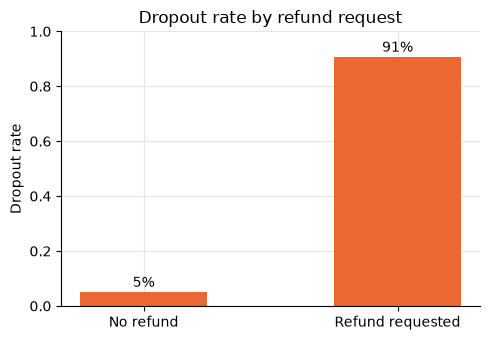

In [4]:
rate = students.groupby("refund_requested").dropped_out.apply(lambda s: (s == "yes").mean())
print(pd.crosstab(students.refund_requested, students.dropped_out, margins=True))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["No refund", "Refund requested"], rate.values, color=COLORS["yes"], width=0.5)
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center")
ax.set_ylim(0, 1)
ax.set_ylabel("Dropout rate")
ax.set_title("Dropout rate by refund request")
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_refund_vs_dropout.png", dpi=150)
plt.show()

### Finding 2 — dropouts fall off the lesson path

lesson_id      L1    L2    L3
dropped_out                  
no           1.00  0.93  0.75
yes          0.98  0.63  0.44


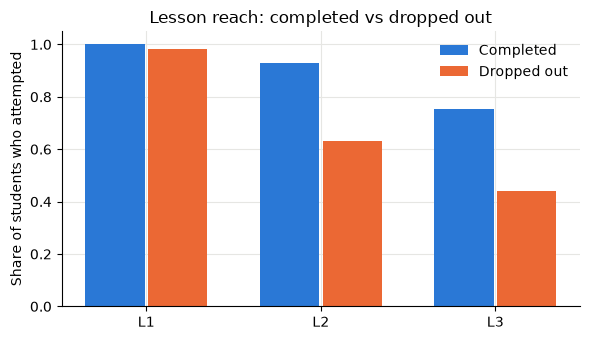

In [5]:
reached = quiz.groupby(["dropped_out", "lesson_id"]).student_id.nunique().unstack()
reached = reached.div(group_sizes, axis=0)  # share of each group that attempted the lesson
print(reached.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
lessons = reached.columns
for i, group in enumerate(["no", "yes"]):
    x = [j + (i - 0.5) * 0.36 for j in range(len(lessons))]
    ax.bar(x, reached.loc[group], width=0.34, color=COLORS[group], label=LABELS[group])
ax.set_xticks(range(len(lessons)), lessons)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Share of students who attempted")
ax.set_title("Lesson reach: completed vs dropped out")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_lesson_reach.png", dpi=150)
plt.show()

### Finding 3 — dropouts score lower, but the groups overlap a lot

             count  mean   std   min   25%   50%   75%    max
dropped_out                                                  
no           375.0  71.6  10.5  41.5  65.1  71.7  79.5  100.0
yes          124.0  61.9  11.7  36.7  53.7  62.7  69.7   85.0


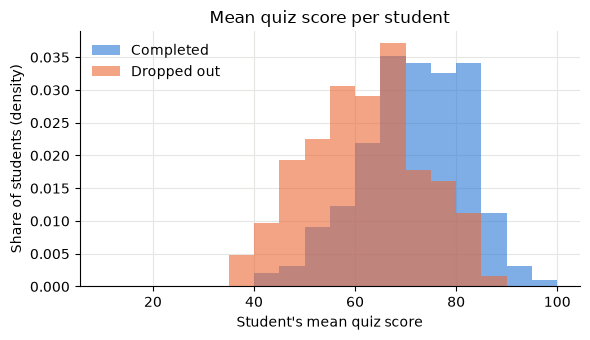

In [6]:
mean_score = quiz.groupby(["student_id", "dropped_out"]).score.mean().reset_index()
print(mean_score.groupby("dropped_out").score.describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
for group in ["no", "yes"]:
    ax.hist(mean_score[mean_score.dropped_out == group].score, bins=range(10, 101, 5),
            alpha=0.6, color=COLORS[group], label=LABELS[group], density=True)
ax.set_xlabel("Student's mean quiz score")
ax.set_ylabel("Share of students (density)")
ax.set_title("Mean quiz score per student")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_mean_score.png", dpi=150)
plt.show()

### Finding 4 — dropouts stop early, so *when* we look matters

             count  mean   std  min   25%   50%   75%    max
dropped_out                                                 
no           375.0  46.9  19.8  6.0  32.0  44.0  59.0  104.0
yes          124.0  19.4  14.1  0.0   9.0  15.0  29.0   54.0


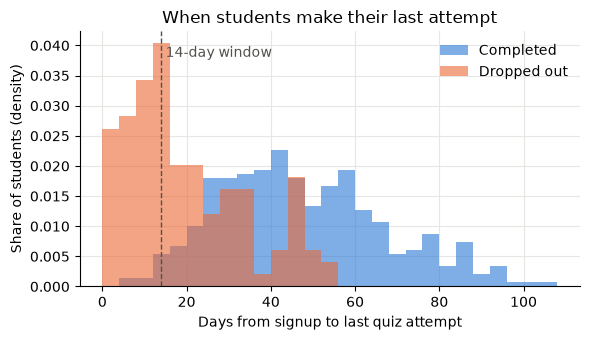

In [7]:
last_day = quiz.groupby(["student_id", "dropped_out"]).days_since_signup.max().reset_index()
print(last_day.groupby("dropped_out").days_since_signup.describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
for group in ["no", "yes"]:
    ax.hist(last_day[last_day.dropped_out == group].days_since_signup, bins=range(0, 110, 4),
            alpha=0.6, color=COLORS[group], label=LABELS[group], density=True)
ax.axvline(WINDOW_DAYS, color="#52514e", linestyle="--", linewidth=1)
ax.text(WINDOW_DAYS + 1, ax.get_ylim()[1] * 0.9, f"{WINDOW_DAYS}-day window", color="#52514e")
ax.set_xlabel("Days from signup to last quiz attempt")
ax.set_ylabel("Share of students (density)")
ax.set_title("When students make their last attempt")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_last_attempt_day.png", dpi=150)
plt.show()

**Findings summary**

1. **`refund_requested` leaks the outcome.** 106 of 117 refund requesters dropped out (91%) vs 19 of 383
   others (5%). A refund is part of leaving, not an early sign of it → excluded from the model.
2. **Dropouts leave between Lesson 1 and Lesson 2.** Nearly everyone attempts L1 (98% vs 100%), but only
   63% of dropouts reach L2 (vs 93%) and 44% reach L3 (vs 75%). → *lessons reached* is a feature.
3. **Dropouts score ~10 points lower** (mean 62 vs 72), but the distributions overlap heavily, so score
   helps but won't separate the groups on its own. → mean / min score are features.
4. **Dropouts stop early.** Median last attempt: day 15 after signup for dropouts vs day 44 for completers.
   So an early-warning model must only look at early activity — features built from full history mostly
   measure *that the student already stopped*. This motivates the time window below.

## 2. Clean (log every decision)

All cleaning lives in `src/data.py`. Each step prints one line and is collected in a log table.
The raw files are never edited.

In [8]:
data = load_clean()
cleaning_log()

[clean] students: filled missing age_group with 'unknown' (21 rows) - keep these students; missing is its own category rather than a guess
[clean] students: filled missing device with 'unknown' (16 rows) - keep these students; missing is its own category rather than a guess
[clean] quiz: dropped scores outside 0-100 (all were 999) (3 rows) - impossible value, looks like a placeholder/error code
[clean] quiz: dropped duplicate attempts (identical except attempt_id) (18 rows) - double-logged rows would inflate attempt counts
[clean] quiz: left missing time_spent_min as missing (95 rows) - missing at a similar rate for both groups; imputed per CV fold inside the model Pipeline
[clean] outcome: mapped dropped_out yes/no to 1/0 (500 rows) - numeric target for modelling


,table,what,rows,why
0,students,filled missing age_group with 'unknown',21,keep these students; missing is its own catego...
1,students,filled missing device with 'unknown',16,keep these students; missing is its own catego...
2,quiz,dropped scores outside 0-100 (all were 999),3,"impossible value, looks like a placeholder/err..."
3,quiz,dropped duplicate attempts (identical except a...,18,double-logged rows would inflate attempt counts
4,quiz,left missing time_spent_min as missing,95,missing at a similar rate for both groups; imp...
5,outcome,mapped dropped_out yes/no to 1/0,500,numeric target for modelling


Why each decision:

| Step | Decision | Why |
|---|---|---|
| Missing `age_group` / `device` | fill with `"unknown"` | only 37 students; dropping them loses outcomes, guessing a value invents data |
| Scores of `999` | drop the 3 rows | impossible on a 0–100 scale, looks like an error code |
| Duplicate attempts | drop 18 copies | same student/lesson/score/time/minute but a new `attempt_id` = logged twice; would inflate attempt counts |
| Missing `time_spent_min` | leave missing here | ~4% of rows, missing at a similar rate for both groups, so not a signal. Filling with a median over *all* students would leak across CV folds, so imputation happens inside the model Pipeline (median, fitted per training fold) |
| `dropped_out` | yes/no → 1/0 | numeric target |

What I deliberately did **not** do: drop the one student with no quiz attempts (zero activity is real
information), or touch `refund_requested` (kept for exploration, excluded from features).

**Rule of thumb used:** cleaning only applies fixed, row-level rules (drop impossible values, drop
duplicates, label missing categories). Anything *learned from the data* — medians, scaling, one-hot
categories — lives in the sklearn Pipeline in `src/model.py`, so it is re-fitted on each training fold.

In [9]:
# Sanity checks after cleaning
assert data["quiz"].score.between(0, 100).all()
assert not data["quiz"].drop(columns="attempt_id").duplicated().any()
assert data["students"][["age_group", "device"]].notna().all().all()
print({name: len(df) for name, df in data.items()})

{'students': 500, 'quiz': 2432, 'outcome': 500}


### Window comparison — how much early activity should the model see?

Features come from each student's first `N` days after signup (`src/features.py`). Same model at
every window: the logistic regression Pipeline from `src/model.py` (median-impute + scale numbers,
one-hot categories, `class_weight="balanced"` because only 25% drop out), 5-fold stratified CV, seed 42.
AUC is shown as mean ± std across the 5 folds.

`dropouts_already_stopped` = share of dropouts whose last quiz attempt is before the window ends.
At that point the window isn't *predicting* their dropout any more — it's watching it happen.

In [10]:
WINDOWS = [7, 14, 21, 28, None]  # None = full history
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

y = data["outcome"].set_index("student_id").dropped_out
last_day = last_attempt_day(data["students"], data["quiz"])
dropout_last_day = last_day[y[last_day.index] == 1]

rows = []
for window in WINDOWS:
    X = build_features(data["students"], data["quiz"], window_days=window)
    s = cv_summary(make_logreg(SEED), X, y[X.index], cv)
    rows.append({
        "window": "full history" if window is None else f"{window} days",
        "auc_mean": s["auc"][0],
        "auc_std": s["auc"][1],
        "precision": s["precision"][0],
        "recall": s["recall"][0],
        "f1": s["f1"][0],
        "dropouts_already_stopped": 1.0 if window is None else (dropout_last_day < window).mean(),
    })

window_results = pd.DataFrame(rows).round(3)
window_results.to_json(JSON_DIR + "p1_window_comparison.json", orient="records", indent=2)
window_results

,window,auc_mean,auc_std,precision,recall,f1,dropouts_already_stopped
0,7 days,0.723,0.064,0.456,0.616,0.523,0.200
1,14 days,0.772,0.040,0.455,0.680,0.544,0.416
2,21 days,0.792,0.026,0.473,0.752,0.578,0.600
3,28 days,0.812,0.026,0.488,0.744,0.587,0.728
4,full history,0.900,0.020,0.591,0.808,0.680,1.000


**Reading the table**

- **Full history is a leak, not a better model.** It has the best scores (AUC 0.90 ± 0.02, F1 0.68), but
  by definition 100% of dropouts have already made their last attempt, so the model is detecting the
  stop, not predicting it. Not usable for early warning.
- **Neighbouring windows are within noise on AUC.** 7 → 14 days is +0.05 but the fold std is 0.04–0.06;
  14 → 21 and 21 → 28 are +0.02 against a std of ~0.03. With 125 dropouts (~25 per test fold) one fold
  can swing AUC a lot. So the table does **not** show that 14 days is the most accurate window — only
  that accuracy rises gently with window length, and that the 7-day model is the least stable (std 0.064).
- **What *is* clear-cut is timing.** The share of dropouts already gone rises fast:
  20% → 42% → 60% → 73%. That is a fact about the data, not a noisy estimate.
- **Why 14 days, then:**
  - It is the longest window where most dropouts (58%) are still active, so there is still someone to
    help. At 21 days most (60%) have already stopped.
  - One week is thin data: 195 of 500 students have no attempt yet at day 7, vs 59 at day 14, and
    the 7-day model's AUC varies most across folds.
  - The extra accuracy from 21–28 days is small and within noise, and is bought by waiting for students
    to leave.
- **Caveat:** 42% of dropouts have already stopped by day 14 — the model is early for the majority, not
  for everyone. A 7-day model is the option if catching the earliest leavers matters more than stability.

→ `WINDOW_DAYS = 14` in `src/features.py`.

## 3. Features

One row per student, built only from quiz attempts in the first `WINDOW_DAYS = 14` days after signup
(`src/features.py`).

| Feature | Why |
|---|---|
| `n_attempts`, `active_days` | engagement; over the full course dropouts attempt less (finding 2) |
| `n_lessons` | progress; over the full course dropouts stall between L1 and L2 (finding 2) — but in the first 14 days it is the *opposite*, see below |
| `mean_score`, `min_score` | struggling students are more likely to leave (finding 3) |
| `mean_time_min` | effort per attempt |
| `days_to_first_attempt` | a slow start is an early warning sign |
| `no_attempts_in_window` | 1 if no attempts in 14 days; marks rows whose score/time were imputed |
| `age_group`, `device`, `country` | context; one-hot encoded in the Pipeline |

For students with no attempts, counts are 0 and `days_to_first_attempt` = 14. Scores and time are left
missing and median-imputed **inside the Pipeline** (fitted on each training fold), with the flag above so
the model can tell an imputed median from a real one.

In [11]:
X = build_features(data["students"], data["quiz"])  # uses WINDOW_DAYS = 14
y = data["outcome"].set_index("student_id").dropped_out[X.index]

print(X.shape, "| dropouts:", y.sum(), "| no attempts in window:", X.no_attempts_in_window.sum())
X[NUMERIC].groupby(y.rename("dropped_out")).mean().round(2).T

(500, 11) | dropouts: 125 | no attempts in window: 59


dropped_out,0,1
n_attempts,1.58,1.90
n_lessons,0.94,1.30
mean_score,71.79,60.86
min_score,68.47,56.24
mean_time_min,24.61,20.66
active_days,1.49,1.82
days_to_first_attempt,6.86,4.64
no_attempts_in_window,0.14,0.05


**Surprise: in the first 14 days, dropouts are *ahead*, not behind.** They start sooner, reach more
lessons, spend less time per attempt and score lower. A plausible reading is *rushing*: moving on to the
next lesson after a weak score instead of retrying, then quitting. (It's synthetic data, so this is a
hypothesis about the pattern, not a claim about real students.) The full-history picture in finding 2 —
dropouts reach fewer lessons — only appears *after* they stop.

## 4. Model + baseline

All four are scored with the same 5-fold stratified CV (seed 42):

- **A — always "no dropout"**: the trivial model; shows why accuracy is misleading at a 25% dropout rate.
- **B — a one-line rule** a course team could run in a spreadsheet: flag if `column <= N`, with `N` picked
  on each *training* fold (best F1), never on the test fold. Two versions:
  - **B1 `n_lessons (in window) >= N`** — follows the EDA above: reaching more lessons early = higher risk.
    (The obvious "low engagement" rule `n_attempts <= N` fails here because the relationship runs the
    other way — see the table just below — so it collapses to "flag everyone".)
  - **B2 `mean_score <= N`** — low early scores = higher risk.
- **Logistic regression**: the Pipeline (impute → scale → one-hot → LR, `class_weight="balanced"`).
- **Random forest**: same preprocessing, 300 trees, `min_samples_leaf=5`. Kept only if clearly better.

Metrics are mean ± std across the 5 folds, at the default 0.5 threshold (threshold is tuned in section 5).

In [12]:
# Why a "few attempts" rule can't work here: dropout rate by attempts in the first 14 days
pd.crosstab(X.n_attempts, y, normalize="index").round(2).rename(columns={0: "completed", 1: "dropped out"})

dropped_out,completed,dropped out
n_attempts,,
0.0,0.90,0.10
1.0,0.76,0.24
2.0,0.69,0.31
3.0,0.81,0.19
4.0,0.58,0.42
5.0,0.38,0.62


In [13]:
models = {
    "A: always 'no dropout'": make_always_no(),
    "B1: n_lessons >= N": ThresholdRule("n_lessons", ">="),
    "B2: mean_score <= N": ThresholdRule("mean_score", "<="),
    "logistic regression": make_logreg(SEED),
    "random forest": make_forest(SEED),
}
results = {name: cv_summary(model, X, y, cv) for name, model in models.items()}

for name in ["B1: n_lessons >= N", "B2: mean_score <= N"]:
    rule = models[name]
    chosen_n = [float(ThresholdRule(rule.column, rule.direction).fit(X.iloc[train], y.iloc[train]).n_)
                for train, _ in cv.split(X, y)]
    print(f"{name}: N chosen on each training fold = {chosen_n}")

pd.DataFrame({name: {m: {"mean": v[0], "std": v[1]} for m, v in r.items()} for name, r in results.items()}) \
    .to_json(JSON_DIR + "p1_model_comparison.json", indent=2)
format_mean_std(results)

B1: n_lessons >= N: N chosen on each training fold = [1.0, 1.0, 1.0, 1.0, 1.0]


B2: mean_score <= N: N chosen on each training fold = [74.0, 67.5, 66.8, 74.0, 73.0]


,accuracy,precision,recall,f1,auc
A: always 'no dropout',0.750 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
B1: n_lessons >= N,0.344 ± 0.045,0.270 ± 0.018,0.952 ± 0.030,0.421 ± 0.025,0.547 ± 0.039
B2: mean_score <= N,0.604 ± 0.019,0.348 ± 0.034,0.696 ± 0.163,0.461 ± 0.064,0.635 ± 0.057
logistic regression,0.714 ± 0.040,0.455 ± 0.055,0.680 ± 0.076,0.544 ± 0.055,0.772 ± 0.040
random forest,0.720 ± 0.030,0.456 ± 0.044,0.616 ± 0.082,0.523 ± 0.055,0.749 ± 0.045


**Reading the table**

- **A shows why accuracy misleads.** Never flagging anyone scores 75% accuracy — better than every real
  model — while catching zero dropouts. With a 25% minority class, accuracy rewards ignoring it, so it is
  not used to pick a model.
- **B1 (`n_lessons >= N`) picks N = 1 on every fold**, i.e. "flag anyone who attempted at all" (~88% of
  students): recall 0.95 but precision 0.27, barely above the 0.25 base rate; F1 0.42, AUC 0.55. Best-F1
  favours this loose cut because recall is cheap at a 25% base rate. The stricter `N = 2` is much more
  precise (~0.54) but catches under a third of dropouts — one feature can't give both.
- **B2 (`mean_score <= N`) is the stronger baseline:** AUC 0.64 ± 0.06, F1 0.46. The chosen N moves
  between 67 and 74 across folds, so its recall is unstable (± 0.16).
- **Logistic regression beats both baselines clearly:** AUC 0.77 ± 0.04 vs 0.64 ± 0.06 for B2 (gap ≈ 0.14,
  more than two fold-stds), F1 0.54 vs 0.46, and steadier across folds. Combining lessons reached *and*
  score is what a single rule can't do.
- **Random forest is not better** (AUC 0.75 ± 0.05, F1 0.52 — slightly worse, within noise). With 500
  students and mostly one-directional signals, a linear model is enough, and it is easier to explain.
  **Dropped; the final model is logistic regression.**

## 5. Evaluate — precision / recall / F1, and choosing the threshold

**Recall matters more than precision here.** A missed at-risk student (false negative) may leave the
course without anyone reaching out. An unneeded nudge (false positive) costs a short message or a few
minutes of a mentor's time, and is mildly helpful even to a student who would have stayed. So we accept
lower precision to catch most dropouts.

**Rule:** using out-of-fold probabilities (each student scored by a model that never saw them), pick the
highest threshold that still gives **recall ≥ 0.8**, then report the precision we pay for it.

⚠️ The threshold is chosen on the same out-of-fold predictions it is evaluated on, so the precision/recall
at that threshold are **slightly optimistic**. A clean estimate would choose the threshold inside each
training fold (nested CV) or on a separate validation set.

In [14]:
TARGET_RECALL = 0.8
final_model = make_logreg(SEED)

oof_risk = cross_val_predict(final_model, X, y, cv=cv, method="predict_proba")[:, 1]
precision, recall, thresholds = precision_recall_curve(y, oof_risk)

# precision/recall have one more entry than thresholds (the end point), so drop the last one.
meets_target = recall[:-1] >= TARGET_RECALL
threshold = thresholds[meets_target].max()  # highest threshold that still reaches the recall target
at_risk = (oof_risk >= threshold).astype(int)

for name, t in [("default 0.5", 0.5), (f"tuned {threshold:.3f}", threshold)]:
    pred = (oof_risk >= t).astype(int)
    print(f"{name:>14}: precision {precision_score(y, pred):.3f} | recall {recall_score(y, pred):.3f} | "
          f"F1 {f1_score(y, pred):.3f} | flagged {pred.sum()} of {len(pred)}")
print("out-of-fold AUC:", round(roc_auc_score(y, oof_risk), 3))

# Fair comparison at the same operating point: rank students by mean score alone (lower = riskier).
# No fitting, so no CV needed. Students with no attempts get the median score (neither end of the ranking).
score_risk = -X.mean_score.fillna(X.mean_score.median())
p_s, r_s, _ = precision_recall_curve(y, score_risk)
print(f"mean_score alone: AUC {roc_auc_score(y, score_risk):.3f} | "
      f"precision at recall >= {TARGET_RECALL}: {p_s[:-1][r_s[:-1] >= TARGET_RECALL].max():.3f}")

print("\nConfusion matrix at tuned threshold (rows = actual, cols = predicted):")
pd.crosstab(y.rename("actual dropout"), pd.Series(at_risk, index=y.index, name="flagged at risk"))

   default 0.5: precision 0.452 | recall 0.680 | F1 0.543 | flagged 188 of 500


   tuned 0.368: precision 0.389 | recall 0.800 | F1 0.524 | flagged 257 of 500
out-of-fold AUC: 0.768
mean_score alone: AUC 0.701 | precision at recall >= 0.8: 0.322

Confusion matrix at tuned threshold (rows = actual, cols = predicted):


flagged at risk,0,1
actual dropout,,
0,218,157
1,25,100


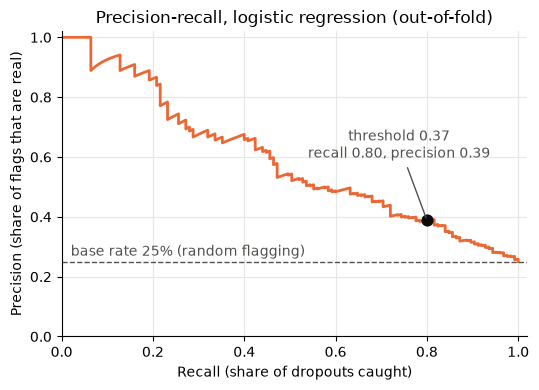

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(recall, precision, color=COLORS["yes"], linewidth=2)
tuned = (precision_score(y, at_risk), recall_score(y, at_risk))
ax.scatter(tuned[1], tuned[0], s=60, color="#0b0b0b", zorder=3)
ax.annotate(f"threshold {threshold:.2f}\nrecall {tuned[1]:.2f}, precision {tuned[0]:.2f}",
            (tuned[1], tuned[0]), xytext=(-20, 45), textcoords="offset points", color="#52514e",
            ha="center", arrowprops={"arrowstyle": "-", "color": "#52514e"})
ax.axhline(y.mean(), color="#52514e", linestyle="--", linewidth=1)
ax.text(0.02, y.mean() + 0.02, f"base rate {y.mean():.0%} (random flagging)", color="#52514e")
ax.set_xlabel("Recall (share of dropouts caught)")
ax.set_ylabel("Precision (share of flags that are real)")
ax.set_title("Precision-recall, logistic regression (out-of-fold)")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_precision_recall.png", dpi=150)
plt.show()

In [16]:
# Out-of-fold risk score + at-risk flag for every student -> used in Part 2.
risk_scores = pd.DataFrame({
    "student_id": X.index,
    "risk_score": oof_risk.round(4),
    "at_risk": at_risk,
    "dropped_out": y.values,
})
risk_scores.to_csv("../outputs/risk_scores.csv", index=False)
print(f"saved {len(risk_scores)} students, {risk_scores.at_risk.sum()} flagged at risk (threshold {threshold:.3f})")
risk_scores.sort_values("risk_score", ascending=False).head()

saved 500 students, 257 flagged at risk (threshold 0.368)


,student_id,risk_score,at_risk,dropped_out
242,S243,0.9914,1,1
131,S132,0.9892,1,1
243,S244,0.9751,1,1
111,S112,0.9698,1,1
301,S302,0.9530,1,1


**Result at the chosen threshold (0.368)**

- **Recall 0.80** — 100 of 125 dropouts flagged; 25 missed.
- **Precision 0.39** — 257 of 500 students flagged (51%); about 3 in 5 flags go to students who would
  have stayed. That is still **1.6× better than random flagging** (base rate 0.25), and better than
  ranking by mean score alone at the same recall (precision 0.32).
- Compared with the default 0.5 threshold: recall 0.68 → 0.80, precision 0.45 → 0.39. We trade 69 more
  flags for 15 more dropouts caught.

**What this means in practice:** flagging half the cohort is fine if the first action is cheap and
helpful to anyone — an automated check-in or the Part 2 feedback on their explanation. If the action were
1:1 mentor time, I would tier it: highest risk scores get a mentor, the rest get the automated nudge.

*(Reminder: threshold chosen on the same out-of-fold predictions it is scored on → these numbers are
slightly optimistic.)*

Saved: `outputs/risk_scores.csv` — `student_id`, `risk_score` (out-of-fold probability), `at_risk` (0/1 at
threshold 0.368), `dropped_out` (actual), for all 500 students.

## 6. Feature importance + what I didn't use

Two views, one chart:
- **LR coefficients** (model fitted on all 500 students). Features are standardised, so sizes are comparable;
  positive = raises dropout risk. Shows *direction*, but correlated features (e.g. `n_attempts` and
  `active_days`) can split or swap weight between them.
- **Permutation importance**: how much test-fold AUC drops when one column is shuffled, averaged over the
  5 CV test folds (20 shuffles each). Measured on unseen students, and per *original* column (a category
  like `country` is shuffled as a whole).

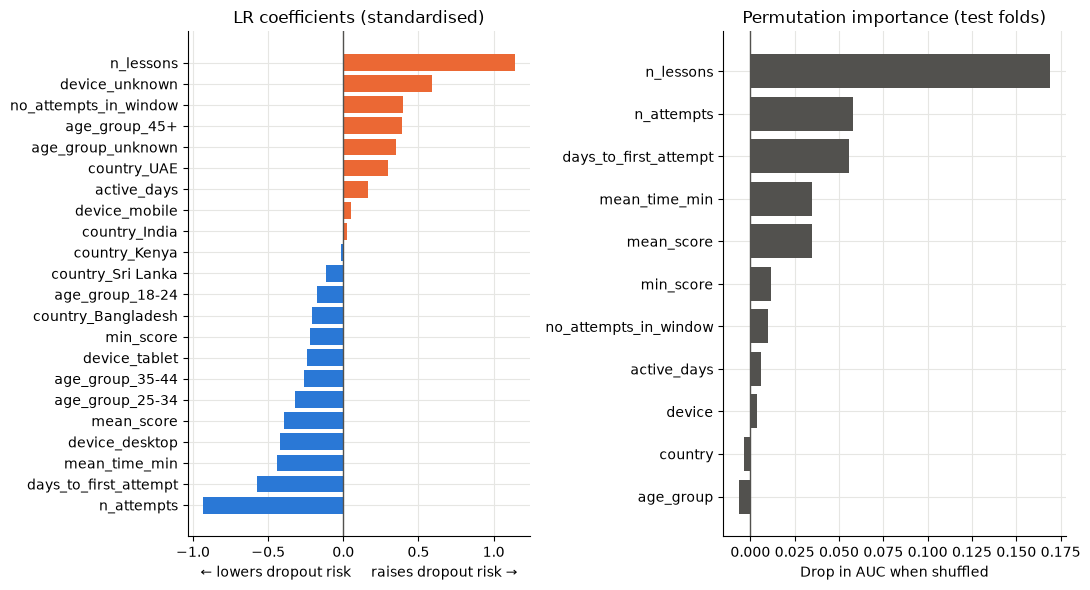

n_lessons                0.169
n_attempts               0.058
days_to_first_attempt    0.056
mean_time_min            0.035
mean_score               0.035
min_score                0.012
no_attempts_in_window    0.010
active_days              0.006
device                   0.004
country                 -0.004
age_group               -0.007


In [17]:
final_model.fit(X, y)
names = [n.split("__", 1)[1] for n in final_model[0].get_feature_names_out()]  # drop "num__"/"cat__"
coefs = pd.Series(final_model[-1].coef_[0], index=names).sort_values()

perm = []
for train, test in cv.split(X, y):
    fold_model = make_logreg(SEED).fit(X.iloc[train], y.iloc[train])
    r = permutation_importance(fold_model, X.iloc[test], y.iloc[test], scoring="roc_auc",
                               n_repeats=20, random_state=SEED)
    perm.append(r.importances_mean)
perm = pd.Series(np.mean(perm, axis=0), index=X.columns).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6))
ax1.barh(coefs.index, coefs.values, color=[COLORS["yes"] if c > 0 else COLORS["no"] for c in coefs])
ax1.axvline(0, color="#52514e", linewidth=1)
ax1.set_title("LR coefficients (standardised)")
ax1.set_xlabel("← lowers dropout risk     raises dropout risk →")
ax2.barh(perm.index, perm.values, color="#52514e")
ax2.axvline(0, color="#52514e", linewidth=1)
ax2.set_title("Permutation importance (test folds)")
ax2.set_xlabel("Drop in AUC when shuffled")
fig.tight_layout()
fig.savefig(CHART_DIR + "p1_feature_importance.png", dpi=150)
plt.show()

print(perm.sort_values(ascending=False).round(3).to_string())

⚠️ **`n_lessons` and `n_attempts` are correlated** (you can't reach 3 lessons with 1 attempt), so their LR
coefficients split the signal between them and **shouldn't be read alone** — e.g. the negative `n_attempts`
coefficient means "more attempts *for the same number of lessons*", not "more attempts is safer". The raw
relationship for the strongest feature is simpler:

In [18]:
lessons_table = pd.DataFrame({
    "students": X.groupby("n_lessons").size(),
    "dropouts": y.groupby(X.n_lessons).sum(),
    "dropout_rate": y.groupby(X.n_lessons).mean().round(2),
})
lessons_table.index = lessons_table.index.astype(int).rename("lessons reached in first 14 days")
lessons_table

,students,dropouts,dropout_rate
lessons reached in first 14 days,,,
0,59,6,0.10
1,374,83,0.22
2,59,28,0.47
3,8,8,1.00


Dropout risk rises with lessons reached in the first two weeks: 10% (none) → 22% (1) → 47% (2). The
3-lesson group is only **8 students** (all 8 dropped out), far too few to trust that 100% — the reliable
contrast is 1 lesson vs 2.

**What drives the predictions** (14-day features)

- **`n_lessons` is by far the strongest** (AUC drops 0.17 when shuffled), and it *raises* risk: reaching
  more lessons in the first two weeks goes with dropping out.
- **`n_attempts` lowers risk once `n_lessons` is in the model.** The two are correlated and should be read
  together: same lessons + more attempts = more retries. So the model's picture is *rushing ahead without
  retrying* → higher risk. (Don't read either coefficient alone.)
- **`days_to_first_attempt`**: starting very fast is a risk sign (negative coefficient), in line with
  the rushing pattern.
- **`mean_score`, `mean_time_min`**: lower score and less time per attempt → higher risk.
- **Demographics add nothing.** `age_group`, `country`, `device` have ~0 or negative permutation
  importance. Larger coefficients like `device_unknown` (+0.6) rest on 16 students and are noise. They
  could be removed with no loss; I kept them for now as they cost nothing.

**What I chose not to use, and why**

| Not used | Why |
|---|---|
| `refund_requested` | 91% of requesters dropped out; a refund is part of leaving, not an early sign (finding 1) |
| Activity after day 14 | 42%+ of dropouts' last attempts fall later; using it measures the stop, not the risk (window comparison) |
| `signup_date` | a calendar date, not behaviour. July signups drop out more (29% vs 21% in June), but that is a cohort effect that wouldn't carry to a new intake |
| Explanations (`explanations.csv`) | no timestamp, so I can't tell if an explanation was written inside the 14-day window; only 60 have labels. Used in Part 2 instead |
| Random forest | not better than LR (section 4) |